# Test hp models

Take the result of the hp and test the nn with this results 

In [1]:
# Libs

import torch # the main pytorch library
from torch import nn # the sub-library containing neural networks
from torch.utils.data import DataLoader, Subset # an object that generates batches of data for training/testing
from torchvision import datasets # popular datasets, architectures and common image transformations
from torchvision.transforms import ToTensor # an easy way to convert PIL images to Tensors

import numpy as np # NumPy, the python array library
import random # for generating random numbers
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split


# Set seeds

SEED = 0 # seed for reproducibility

random.seed(SEED) # set the seed for random numbers
np.random.seed(SEED) # set the seed for numpy arrays


# Download training data
# Build validation data
# Download test data

# Parameters
validation_ratio = 0.2

# Download training data from open datasets
training_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=True,  # this is the training data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


# Split dataset into training and validation sets
# train and validation data
num_samples = len(training_data)
num_validation_samples = int(validation_ratio * num_samples)
num_training_samples = num_samples - num_validation_samples

# First num_training_samples are for training 
# Last num_validation_samples are for validation
train_data = Subset(training_data, range(num_training_samples))
validation_data = Subset(training_data, range(num_training_samples, num_samples))



# Download test data from open datasets
test_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=False,  # this is the test data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


# Define data loader (specifing batch size)

batch_size = 64 # the size of input data took for one iteration

# Create data loaders.
# Create data loaders
train_dataloader = DataLoader(train_data, batch_size=batch_size)
validation_dataloader = DataLoader(validation_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

# N is batch size; 
# C is number of channels;
# H is height of image; 
# W is width of image
for X, y in train_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in validation_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break


# Set the device 
device = ( # check if gpu is available
    "cuda"
    if torch.cuda.is_available() # use gpu
    else "mps" # use mps
    if torch.backends.mps.is_available() # use mps
    else "cpu" # use cpu
)
print(f"Using {device} device\n")

# A model in which you can specify: 
# the number of hidden units,
# the activation function,
# whether to initialize the weights or not

class flexible_NN_units(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_size1 = 512,
                 hidden_size2 = 512,
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()
        self.linear_relu_stack = nn.Sequential( # create a sequence of layers
            nn.Linear(input_size, hidden_size1), # linear layer from 28*28 to 512 (28*28 is the size of the input image, 512 is the size of the output tensor)
            self.activation_function,  # activation function
            nn.Linear(hidden_size1, hidden_size2), # linear layer from 512 to 512 (512 is the size of the input tensor, 512 is the size of the output tensor)
            self.activation_function, # activation function
            nn.Linear(hidden_size2, output_size) # linear layer from 512 to 10 (512 is the size of the input tensor, 10 is the size of the output tensor)
        )
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)



# A model in which you can specify: 
# the number of hidden layers and units,
# the activation function,
# whether to initialize the weights or not


class flexible_NN_layers(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_sizes = [512,512],
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()

        # Create a list to hold the layers
        layers = []
        previous_size = input_size

        # Add hidden layers dynamically
        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(self.activation_function)
            previous_size = hidden_size
        layers.append(nn.Linear(previous_size, output_size)) # Add the final output layer

        # Create a sequential container with the layers
        # You shoould pass a list of layers to the Sequential container, one by one. 
        # You can do this by using the * operator to unpack the list of layers
        # This is done to avoid of passing a list of layers to the Sequential container (that is not correct)
        self.linear_relu_stack = nn.Sequential(*layers)
      
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)


# Train and test functions

def train(dataloader, model, loss_fn, optimizer): # create a training function
    size = len(dataloader.dataset) # get the size of the dataset
    model.train() # set the model to training mode
    train_loss = 0.0 # initialise the training loss
    for batch, (X, y) in enumerate(dataloader): # iterate over the data
        X, y = X.to(device), y.to(device) # send the input data to the device

        # Compute prediction error
        pred = model(X) # get the model's prediction
        loss = loss_fn(pred, y) # compute the loss (between the model's prediction and the actual value)

        # Backpropagation
        loss.backward() # backpropagate the loss
        optimizer.step() # adjust the model parameters
        optimizer.zero_grad() # reset the gradients

        train_loss += loss.item()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X) # get the loss and the current batch
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
    
    train_loss /= len(dataloader)
    return train_loss




def test(dataloader, model, loss_fn): # create a test function
    size = len(dataloader.dataset)
    num_batches = len(dataloader) # get the number of batches
    model.eval() # set the model to evaluation mode (test correspondece of model.train())
    test_loss, correct = 0, 0 # initialise the test loss and the number of correct predictions
    with torch.no_grad(): # disable gradient calculation
        for X, y in dataloader: # iterate over the data
            X, y = X.to(device), y.to(device) # send the input data to the device
            pred = model(X) # get the model's prediction
            test_loss += loss_fn(pred, y).item() # compute the loss
            correct += (pred.argmax(1) == y).type(torch.float).sum().item() # compute the number of correct predictions
    test_loss /= num_batches # compute the average loss
    correct /= size # compute the accuracy
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return test_loss, 100*correct



# All in one function

def train_and_test_model(epochs, model, loss_fn, optimizer, train_dataloader, test_dataloader):
    train_loss_history = []
    test_loss_history = []
    accuracy_history = []

    for t in range(epochs):
        print(f"Epoch {t+1}\n-------------------------------")
        train_loss = train(train_dataloader, model, loss_fn, optimizer)
        test_loss, accuracy = test(test_dataloader, model, loss_fn)

        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        accuracy_history.append(accuracy)

    print("Done!")
    return train_loss_history, test_loss_history, accuracy_history


Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Using cpu device



## Tests

In [7]:
# Default parameters
input_size = 28*28
output_size = 10
std_hidden_sizes = [512,512]
std_nn_activation_function = nn.ReLU
std_initialize_weights = False
std_nn_learning_rate = 0.001

epochs = 30

In [11]:
# v4 parameters
input_size = 28*28
v3_1_hidden_sizes = [369, 584, 264, 429, 234]
v3_2_hidden_sizes = [574, 122, 452, 176, 59] # v3 first run: [369, 584, 264, 429, 234], second run: [574, 122, 452, 176, 59]
tun_activation_function = nn.LeakyReLU
tun_initialize_weights = True
tun_learning_rate = 0.0096

epochs = 30

In [12]:
# v4 parameters
input_size = 28*28
v4_1_hidden_sizes = [438, 487, 254, 326, 258]
v4_2_hidden_sizes = [333, 377, 560, 319, 537, 261] # v4 first run: [438, 487, 254, 326, 258], second run: [333, 377, 560, 319, 537, 261]

epochs = 30

In [25]:
# v5 parameters 
v5_1_hidden_sizes = [347, 332, 145, 445, 441]

In [9]:
model = flexible_NN_layers(
    input_size=input_size,
    hidden_sizes=std_hidden_sizes,
    output_size=output_size,
    activation_function=std_nn_activation_function,
    initialize_weights=std_initialize_weights).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr = std_nn_learning_rate)

std_train_loss_history, std_test_loss_history, std_accuracy_history = train_and_test_model(
    epochs = epochs, 
    model = model,
    loss_fn = loss_fn,
    optimizer = optimizer,
    train_dataloader = train_dataloader,
    test_dataloader = test_dataloader)


Epoch 1
-------------------------------
loss: 2.309195  [   64/48000]
loss: 2.294966  [ 6464/48000]
loss: 2.277423  [12864/48000]
loss: 2.273593  [19264/48000]
loss: 2.253365  [25664/48000]
loss: 2.227504  [32064/48000]
loss: 2.236518  [38464/48000]
loss: 2.198843  [44864/48000]
Test Error: 
 Accuracy: 38.4%, Avg loss: 2.196744 

Epoch 2
-------------------------------
loss: 2.201531  [   64/48000]
loss: 2.191893  [ 6464/48000]
loss: 2.146508  [12864/48000]
loss: 2.164381  [19264/48000]
loss: 2.116655  [25664/48000]
loss: 2.065398  [32064/48000]
loss: 2.093541  [38464/48000]
loss: 2.016433  [44864/48000]
Test Error: 
 Accuracy: 54.7%, Avg loss: 2.020606 

Epoch 3
-------------------------------
loss: 2.034575  [   64/48000]
loss: 2.015984  [ 6464/48000]
loss: 1.922625  [12864/48000]
loss: 1.965089  [19264/48000]
loss: 1.867198  [25664/48000]
loss: 1.806308  [32064/48000]
loss: 1.837048  [38464/48000]
loss: 1.725364  [44864/48000]
Test Error: 
 Accuracy: 61.5%, Avg loss: 1.737249 

Epoc

In [13]:
hidden_sizes_list = [v3_1_hidden_sizes, v3_2_hidden_sizes, v4_1_hidden_sizes, v4_2_hidden_sizes]
tun_train_loss_history_list = []
tun_test_loss_history_list = []
tun_accuracy_history_list = []

for hidden_sizes in hidden_sizes_list:

    model_tuned = flexible_NN_layers(
        input_size=input_size,
        hidden_sizes=hidden_sizes,
        output_size=output_size,
        activation_function=tun_activation_function,
        initialize_weights=tun_initialize_weights).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model_tuned.parameters(), lr = tun_learning_rate)

    train_data, test_data, accuracy_data = train_and_test_model(
        epochs = epochs, 
        model = model_tuned,
        loss_fn = loss_fn,
        optimizer = optimizer,
        train_dataloader = train_dataloader,
        test_dataloader = test_dataloader)
    
    tun_train_loss_history_list.append(train_data)
    tun_test_loss_history_list.append(test_data)
    tun_accuracy_history_list.append(accuracy_data)

Epoch 1
-------------------------------
loss: 2.311604  [   64/48000]
loss: 1.843775  [ 6464/48000]
loss: 1.045261  [12864/48000]
loss: 0.982181  [19264/48000]
loss: 0.770696  [25664/48000]
loss: 0.699675  [32064/48000]
loss: 0.783908  [38464/48000]
loss: 0.693449  [44864/48000]
Test Error: 
 Accuracy: 78.6%, Avg loss: 0.616594 

Epoch 2
-------------------------------
loss: 0.515194  [   64/48000]
loss: 0.621524  [ 6464/48000]
loss: 0.455702  [12864/48000]
loss: 0.652547  [19264/48000]
loss: 0.592076  [25664/48000]
loss: 0.539271  [32064/48000]
loss: 0.650675  [38464/48000]
loss: 0.660043  [44864/48000]
Test Error: 
 Accuracy: 81.8%, Avg loss: 0.515447 

Epoch 3
-------------------------------
loss: 0.391013  [   64/48000]
loss: 0.529072  [ 6464/48000]
loss: 0.382830  [12864/48000]
loss: 0.544971  [19264/48000]
loss: 0.506175  [25664/48000]
loss: 0.493524  [32064/48000]
loss: 0.594495  [38464/48000]
loss: 0.631745  [44864/48000]
Test Error: 
 Accuracy: 83.3%, Avg loss: 0.476978 

Epoc

In [26]:
model_tuned = flexible_NN_layers(
    input_size=input_size,
    hidden_sizes= v5_1_hidden_sizes,
    output_size=output_size,
    activation_function=tun_activation_function,
    initialize_weights=tun_initialize_weights).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_tuned.parameters(), lr = tun_learning_rate)

v5_1_train_data, v5_1_test_data, v5_1_accuracy_data = train_and_test_model(
    epochs = epochs, 
    model = model_tuned,
    loss_fn = loss_fn,
    optimizer = optimizer,
    train_dataloader = train_dataloader,
    test_dataloader = test_dataloader)



Epoch 1
-------------------------------
loss: 2.328447  [   64/48000]
loss: 1.931818  [ 6464/48000]
loss: 1.108932  [12864/48000]
loss: 1.019688  [19264/48000]
loss: 0.810375  [25664/48000]
loss: 0.729830  [32064/48000]
loss: 0.818206  [38464/48000]
loss: 0.724576  [44864/48000]
Test Error: 
 Accuracy: 77.7%, Avg loss: 0.659899 

Epoch 2
-------------------------------
loss: 0.571353  [   64/48000]
loss: 0.665908  [ 6464/48000]
loss: 0.493517  [12864/48000]
loss: 0.647852  [19264/48000]
loss: 0.631982  [25664/48000]
loss: 0.533195  [32064/48000]
loss: 0.632131  [38464/48000]
loss: 0.618944  [44864/48000]
Test Error: 
 Accuracy: 81.7%, Avg loss: 0.535204 

Epoch 3
-------------------------------
loss: 0.396585  [   64/48000]
loss: 0.538090  [ 6464/48000]
loss: 0.392939  [12864/48000]
loss: 0.541401  [19264/48000]
loss: 0.538643  [25664/48000]
loss: 0.474824  [32064/48000]
loss: 0.546947  [38464/48000]
loss: 0.582646  [44864/48000]
Test Error: 
 Accuracy: 82.9%, Avg loss: 0.490255 

Epoc

## Plots

In [14]:
import plot as plot 

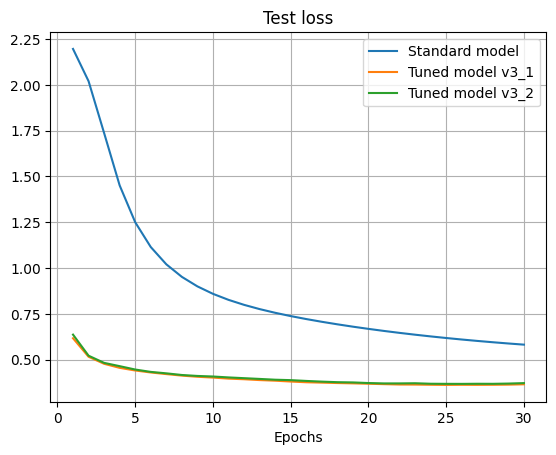

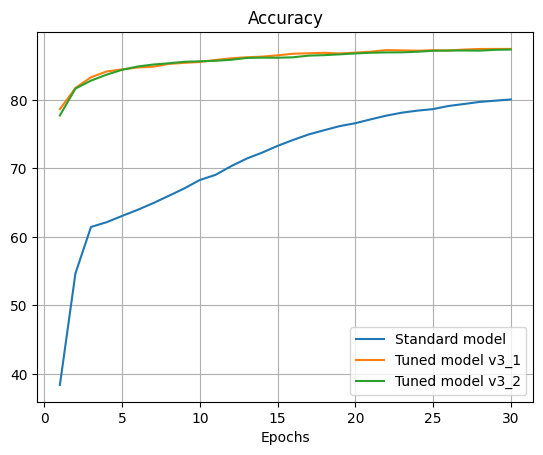

In [20]:
# std vs tuned v3_1 vs v3_3

plot.plot_3_histories(
    std_test_loss_history, 
    tun_test_loss_history_list[0], # v3_1
    tun_test_loss_history_list[1], # v3_2
    "Test loss",
    "Standard model",
    "Tuned model v3_1",
    "Tuned model v3_2")


# std vs tuned v3_1 vs v3_3

plot.plot_3_histories(
    std_accuracy_history, 
    tun_accuracy_history_list[0], # v3_1
    tun_accuracy_history_list[1], # v3_2
    "Accuracy",
    "Standard model",
    "Tuned model v3_1",
    "Tuned model v3_2")

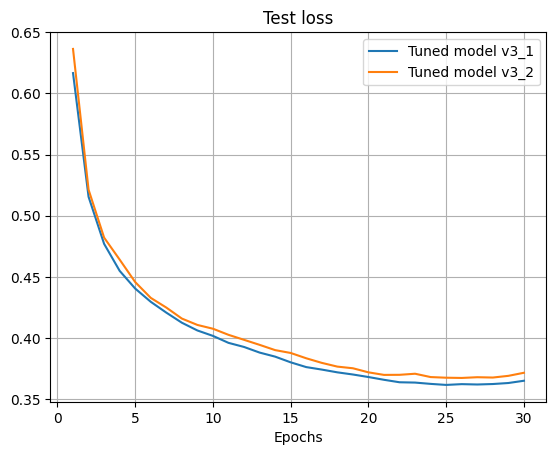

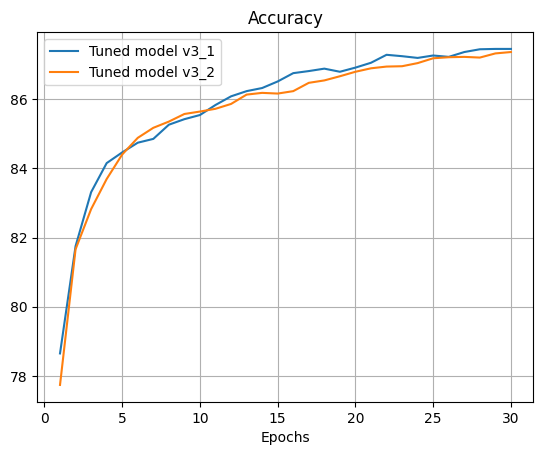

In [21]:
# v3 comparison 

plot.plot_2_histories(
    tun_test_loss_history_list[0], # v3_1
    tun_test_loss_history_list[1], # v3_2
    "Test loss",
    "Tuned model v3_1",
    "Tuned model v3_2")

plot.plot_2_histories(
    tun_accuracy_history_list[0], # v3_1
    tun_accuracy_history_list[1], # v3_2
    "Accuracy",
    "Tuned model v3_1",
    "Tuned model v3_2")

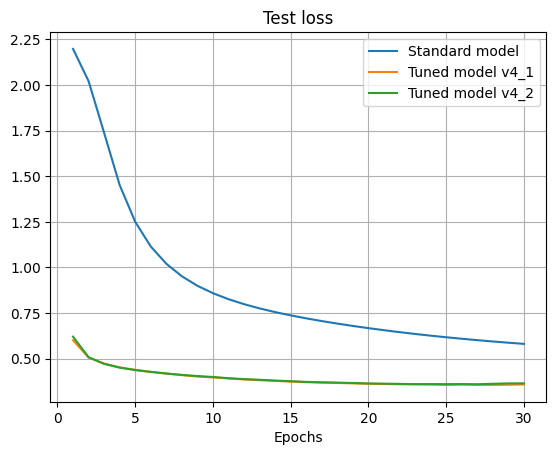

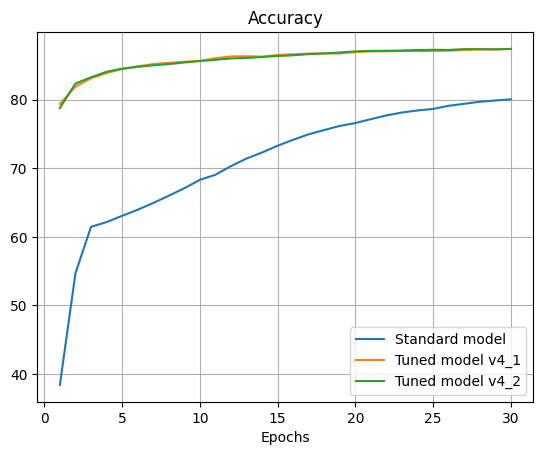

In [22]:
# std vs v4_1 vs v4_2

plot.plot_3_histories(
    std_test_loss_history, 
    tun_test_loss_history_list[2], # v4_1
    tun_test_loss_history_list[3], # v4_2
    "Test loss",
    "Standard model",
    "Tuned model v4_1",
    "Tuned model v4_2")

plot.plot_3_histories(
    std_accuracy_history, 
    tun_accuracy_history_list[2], # v4_1
    tun_accuracy_history_list[3], # v4_2
    "Accuracy",
    "Standard model",
    "Tuned model v4_1",
    "Tuned model v4_2")

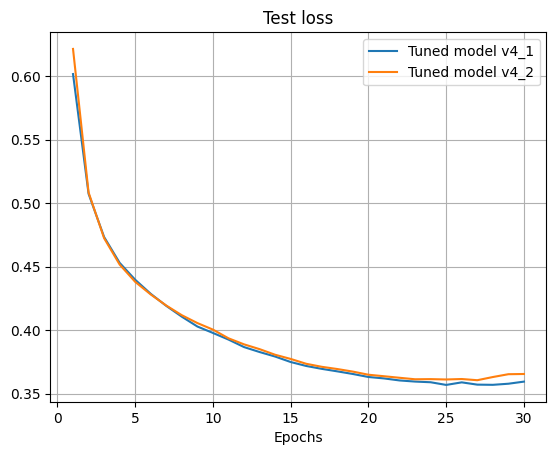

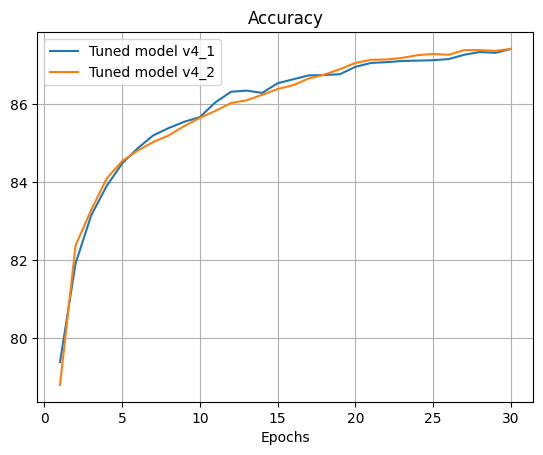

In [23]:
# v4 comparison 

plot.plot_2_histories(
    tun_test_loss_history_list[2], # v4_1
    tun_test_loss_history_list[3], # v4_2
    "Test loss",
    "Tuned model v4_1",
    "Tuned model v4_2")

plot.plot_2_histories(
    tun_accuracy_history_list[2], # v4_1
    tun_accuracy_history_list[3], # v4_2
    "Accuracy",
    "Tuned model v4_1",
    "Tuned model v4_2")

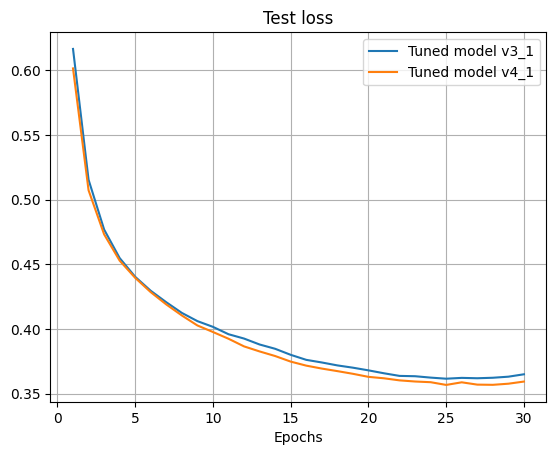

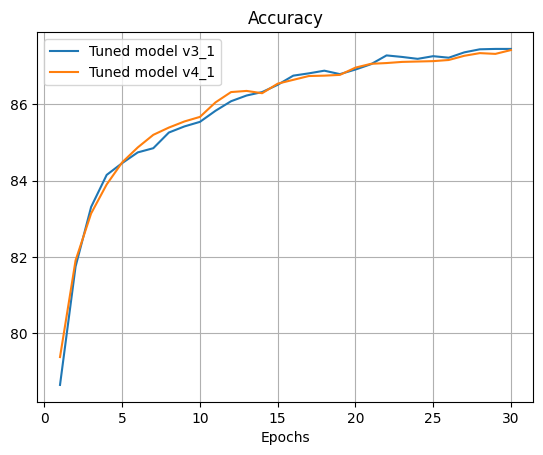

In [24]:
# v4 best vs v3 best

plot.plot_2_histories(
    tun_test_loss_history_list[0], # v3_1
    tun_test_loss_history_list[2], # v4_1
    "Test loss",
    "Tuned model v3_1",
    "Tuned model v4_1")

plot.plot_2_histories(
    tun_accuracy_history_list[0], # v3_1
    tun_accuracy_history_list[2], # v4_1
    "Accuracy",
    "Tuned model v3_1",
    "Tuned model v4_1")

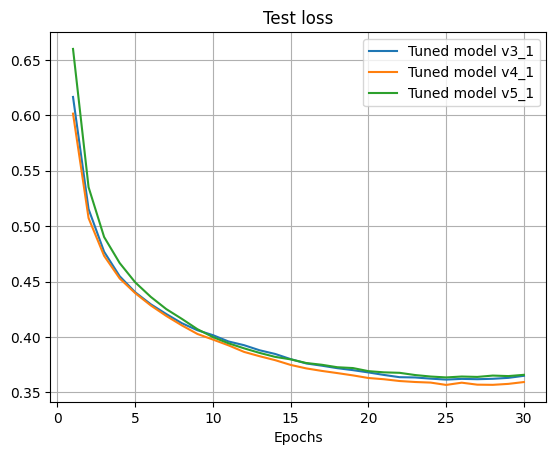

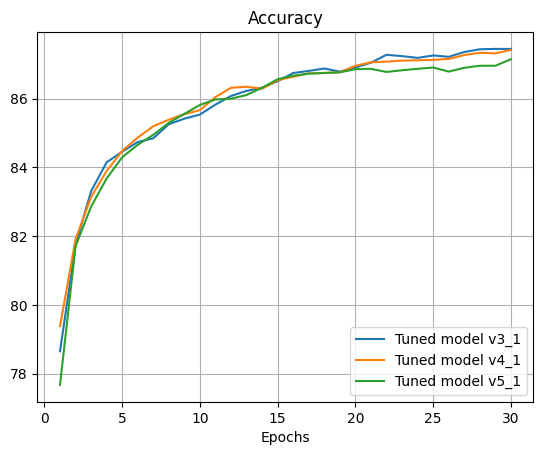

In [28]:
# v4 best vs v3 best vs v5

plot.plot_3_histories(
    tun_test_loss_history_list[0], # v3_1
    tun_test_loss_history_list[2], # v4_1
    v5_1_test_data, # v5_1
    "Test loss",
    "Tuned model v3_1",
    "Tuned model v4_1",
    "Tuned model v5_1")

plot.plot_3_histories(
    tun_accuracy_history_list[0], # v3_1
    tun_accuracy_history_list[2], # v4_1
    v5_1_accuracy_data, # v5_1
    "Accuracy",
    "Tuned model v3_1",
    "Tuned model v4_1",
    "Tuned model v5_1")